<a href="https://colab.research.google.com/github/halwala/-Msinterface-Technologies/blob/main/Bitcoin_Heist_BigDataAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Load Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install dask[complete] dask-ml pyarrow fastparquet pandas matplotlib seaborn xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.0/150.0 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.9/94.9 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 51.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.5/322.5 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 110.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.4/259.4 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.4/90.4 kB 6.2 MB/s eta 0:00:00


In [ ]:
# Import essential libraries for data analysis
import dask.dataframe as dd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from datetime import datetime
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings('ignore')


# Set visualization style
plt.style.use('default')
sns.set_palette("husl")

# Configure display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Set figure size defaults
plt.rcParams['figure.figsize'] = (12, 8)

print("All libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")
print(f"Sklearn version: {sklearn.__version__}")
import dask # Import the top-level dask to get the version
print(f"Dask version: {dask.__version__}")

All libraries imported successfully!
Pandas version: 2.2.2
NumPy version: 2.0.2
Matplotlib version: 3.10.0
Seaborn version: 0.13.2
Sklearn version: 1.6.1
Dask version: 2025.7.0


In [ ]:
import dask.dataframe as dd

file_path = '/content/drive/MyDrive/bitcoin heist/BitcoinHeistData.csv'

# Load CSV with Dask
df = dd.read_csv(file_path, assume_missing=True)

In [ ]:
# Get numerical columns (int and float types)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Get categorical columns (object/string types)
categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['year', 'day', 'length', 'weight', 'count', 'looped', 'neighbors', 'income']
Categorical columns: ['address', 'label']


In [ ]:
# Get dataset shape
total_rows = df.shape[0].compute()  # Get total rows using compute()
total_cols = df.shape[1]  # No need to compute, it's already an integer

# Print the dataset shape
print(f"\nDataset shape: {total_rows:,} rows × {total_cols} columns")

# Display first few rows (this is a Dask operation, so we need to use compute)
first_few_rows = df.head(5)  # This returns a Pandas DataFrame
print(f"\nFirst 5 rows:")
print(first_few_rows)  # No need for .compute() here since head() already returns Pandas


Dataset shape: 2,916,697 rows × 10 columns

First 5 rows:
                              address    year    day  length    weight  count  looped  neighbors       income            label
0   111K8kZAEnJg245r2cM6y9zgJGHZtJPy6  2017.0   11.0    18.0  0.008333    1.0     0.0        2.0  100050000.0  princetonCerber
1  1123pJv8jzeFQaCV4w644pzQJzVWay2zcA  2016.0  132.0    44.0  0.000244    1.0     0.0        1.0  100000000.0   princetonLocky
2  112536im7hy6wtKbpH1qYDWtTyMRAcA2p7  2016.0  246.0     0.0  1.000000    1.0     0.0        2.0  200000000.0  princetonCerber
3  1126eDRw2wqSkWosjTCre8cjjQW8sSeWH7  2016.0  322.0    72.0  0.003906    1.0     0.0        2.0   71200000.0  princetonCerber
4  1129TSjKtx65E35GiUo4AYVeyo48twbrGX  2016.0  238.0   144.0  0.072848  456.0     0.0        1.0  200000000.0   princetonLocky


In [ ]:
# Display Dask DataFrame information
df.info()

<class 'dask.dataframe.dask_expr.DataFrame'>
Columns: 10 entries, address to label
dtypes: float64(8), string(2)

In [ ]:
# Summary of data types
print(df.dtypes)

address      string[pyarrow]
year                 float64
day                  float64
length               float64
weight               float64
count                float64
looped               float64
neighbors            float64
income               float64
label        string[pyarrow]
dtype: object


In [ ]:
# Basic Dstaset Information
print("\n BASIC DATASET INFORMATION")
print(f"Number of partitions: {df.npartitions}")


 BASIC DATASET INFORMATION
Number of partitions: 3


In [ ]:
# Display basic descriptive statistics
print(df.describe().compute())

               year           day        length        weight         count        looped     neighbors        income
count  2.916697e+06  2.916697e+06  2.916697e+06  2.916697e+06  2.916697e+06  2.916697e+06  2.916697e+06  2.916697e+06
mean   2.014475e+03  1.814572e+02  4.500859e+01  5.455192e-01  7.216446e+02  2.385067e+02  2.206516e+00  4.464889e+09
std    2.257398e+00  1.040118e+02  5.898236e+01  3.674255e+00  1.689676e+03  9.663217e+02  1.791877e+01  1.626860e+11
min    2.011000e+03  1.000000e+00  0.000000e+00  3.606469e-94  1.000000e+00  0.000000e+00  1.000000e+00  3.000000e+07
25%    2.012000e+03  1.080000e+02  2.000000e+00  6.250000e-02  1.000000e+00  0.000000e+00  2.000000e+00  1.102859e+08
50%    2.016000e+03  1.990000e+02  2.000000e+01  4.988463e-01  2.000000e+00  0.000000e+00  2.000000e+00  4.705849e+08
75%    2.017000e+03  2.870000e+02  1.380000e+02  1.000000e+00  1.356000e+03  1.000000e+00  2.000000e+00  2.662735e+09
max    2.018000e+03  3.650000e+02  1.440000e+02  1.94374

In [ ]:
# Check for missing values
print(df.isnull().sum().compute())

address      0
year         0
day          0
length       0
weight       0
count        0
looped       0
neighbors    0
income       0
label        0
dtype: int64


In [ ]:
# Check for duplicate rows
# Compute the Dask DataFrame to a Pandas DataFrame before checking for duplicates
df_pandas = df.compute()
num_duplicates = df_pandas.duplicated().sum()

print("Number of duplicate rows:", num_duplicates)

Number of duplicate rows: 0


In [ ]:
# Assuming your Dask DataFrame is named 'df'
df = df.rename(columns={'label': 'malware_type_classified'})

# To check the new column name
df.columns


Index(['address', 'year', 'day', 'length', 'weight', 'count', 'looped', 'neighbors', 'income', 'malware_type_classified'], dtype='object')

In [ ]:
# Get value counts and convert to float
value_counts = df['malware_type_classified'].value_counts().astype(float)

# Compute to see the result
print(value_counts.compute())


malware_type_classified
montrealAPT                         11.0
montrealComradeCircle                1.0
montrealCryptXXX                  2419.0
montrealDMALocker                  251.0
montrealDMALockerv3                354.0
montrealEDA2                         6.0
montrealFlyper                       9.0
montrealGlobev3                     34.0
montrealVenusLocker                  7.0
montrealWannaCry                    28.0
montrealXLockerv5.0                  7.0
paduaJigsaw                          2.0
paduaKeRanger                       10.0
montrealGlobe                       32.0
montrealGlobeImposter               55.0
montrealJigSaw                       4.0
montrealRazy                        13.0
montrealSam                          1.0
paduaCryptoWall                  12390.0
montrealCryptConsole                 7.0
montrealCryptoLocker              9315.0
montrealCryptoTorLocker2015         55.0
montrealNoobCrypt                  483.0
montrealSamSam                   

In [ ]:
import pandas as pd
import numpy as np

# Define the list of heist malware types
heist_malware = [
    # Major Ransomware Families (High Sample Count)
    'paduaCryptoWall',              # 12,390 samples
    'montrealCryptoLocker',         # 9,315 samples
    'princetonCerber',              # 9,223 samples
    'princetonLocky',               # 6,625 samples
    'montrealCryptXXX',             # 2,419 samples

    # Medium-scale Ransomware
    'montrealNoobCrypt',            # 483 samples
    'montrealDMALockerv3',          # 354 samples
    'montrealDMALocker',            # 251 samples
    'montrealSamSam',               # 62 samples
    'montrealGlobeImposter',        # 55 samples
    'montrealCryptoTorLocker2015',  # 55 samples

    # Globe Ransomware Family
    'montrealGlobev3',              # 34 samples
    'montrealGlobe',                # 32 samples

    # Notable Ransomware
    'montrealWannaCry',             # 28 samples
    'montrealRazy',                 # 13 samples
    'paduaKeRanger',                # 10 samples (Mac ransomware)

    # Locker Variants
    'montrealFlyper',               # 9 samples
    'montrealXTPLocker',            # 8 samples
    'montrealVenusLocker',          # 7 samples
    'montrealXLockerv5.0',          # 7 samples
    'montrealCryptConsole',         # 7 samples
    'montrealEDA2',                 # 6 samples

    # Jigsaw Family
    'montrealJigSaw',               # 4 samples
    'paduaJigsaw',                  # 2 samples

    # Small-scale Ransomware
    'montrealXLocker',              # 1 sample
    'montrealSam'                   # 1 sample
]

# Function to classify as 'heist' or 'non-heist'
def classify_malware_type(malware_type):
    if pd.isna(malware_type): # Handle potential NaN values
        return 'non-heist' # Or a different category like 'unknown'
    elif malware_type in heist_malware:
        return 'heist'
    else:
        return 'non-heist'


# Apply the classification to the malware_type_classified column and create a new 'malware_type' column
df['malware_type'] = df['malware_type_classified'].map(classify_malware_type)

# Check the result
df.head()

,address,year,day,length,weight,count,looped,neighbors,income,malware_type_classified,malware_type
0,111K8kZAEnJg245r2cM6y9zgJGHZtJPy6,2017.0,11.0,18.0,0.008333,1.0,0.0,2.0,100050000.0,princetonCerber,heist
1,1123pJv8jzeFQaCV4w644pzQJzVWay2zcA,2016.0,132.0,44.0,0.000244,1.0,0.0,1.0,100000000.0,princetonLocky,heist
2,112536im7hy6wtKbpH1qYDWtTyMRAcA2p7,2016.0,246.0,0.0,1.000000,1.0,0.0,2.0,200000000.0,princetonCerber,heist
3,1126eDRw2wqSkWosjTCre8cjjQW8sSeWH7,2016.0,322.0,72.0,0.003906,1.0,0.0,2.0,71200000.0,princetonCerber,heist
4,1129TSjKtx65E35GiUo4AYVeyo48twbrGX,2016.0,238.0,144.0,0.072848,456.0,0.0,1.0,200000000.0,princetonLocky,heist


In [ ]:
value_counts = df['malware_type'].value_counts()
print(value_counts.compute())


malware_type
non-heist    2875296
heist          41401
Name: count, dtype: int64


In [ ]:
# Drop the 'malware_type' column
df = df.drop('malware_type_classified', axis=1)
df.head()

,address,year,day,length,weight,count,looped,neighbors,income,malware_type
0,111K8kZAEnJg245r2cM6y9zgJGHZtJPy6,2017.0,11.0,18.0,0.008333,1.0,0.0,2.0,100050000.0,heist
1,1123pJv8jzeFQaCV4w644pzQJzVWay2zcA,2016.0,132.0,44.0,0.000244,1.0,0.0,1.0,100000000.0,heist
2,112536im7hy6wtKbpH1qYDWtTyMRAcA2p7,2016.0,246.0,0.0,1.000000,1.0,0.0,2.0,200000000.0,heist
3,1126eDRw2wqSkWosjTCre8cjjQW8sSeWH7,2016.0,322.0,72.0,0.003906,1.0,0.0,2.0,71200000.0,heist
4,1129TSjKtx65E35GiUo4AYVeyo48twbrGX,2016.0,238.0,144.0,0.072848,456.0,0.0,1.0,200000000.0,heist


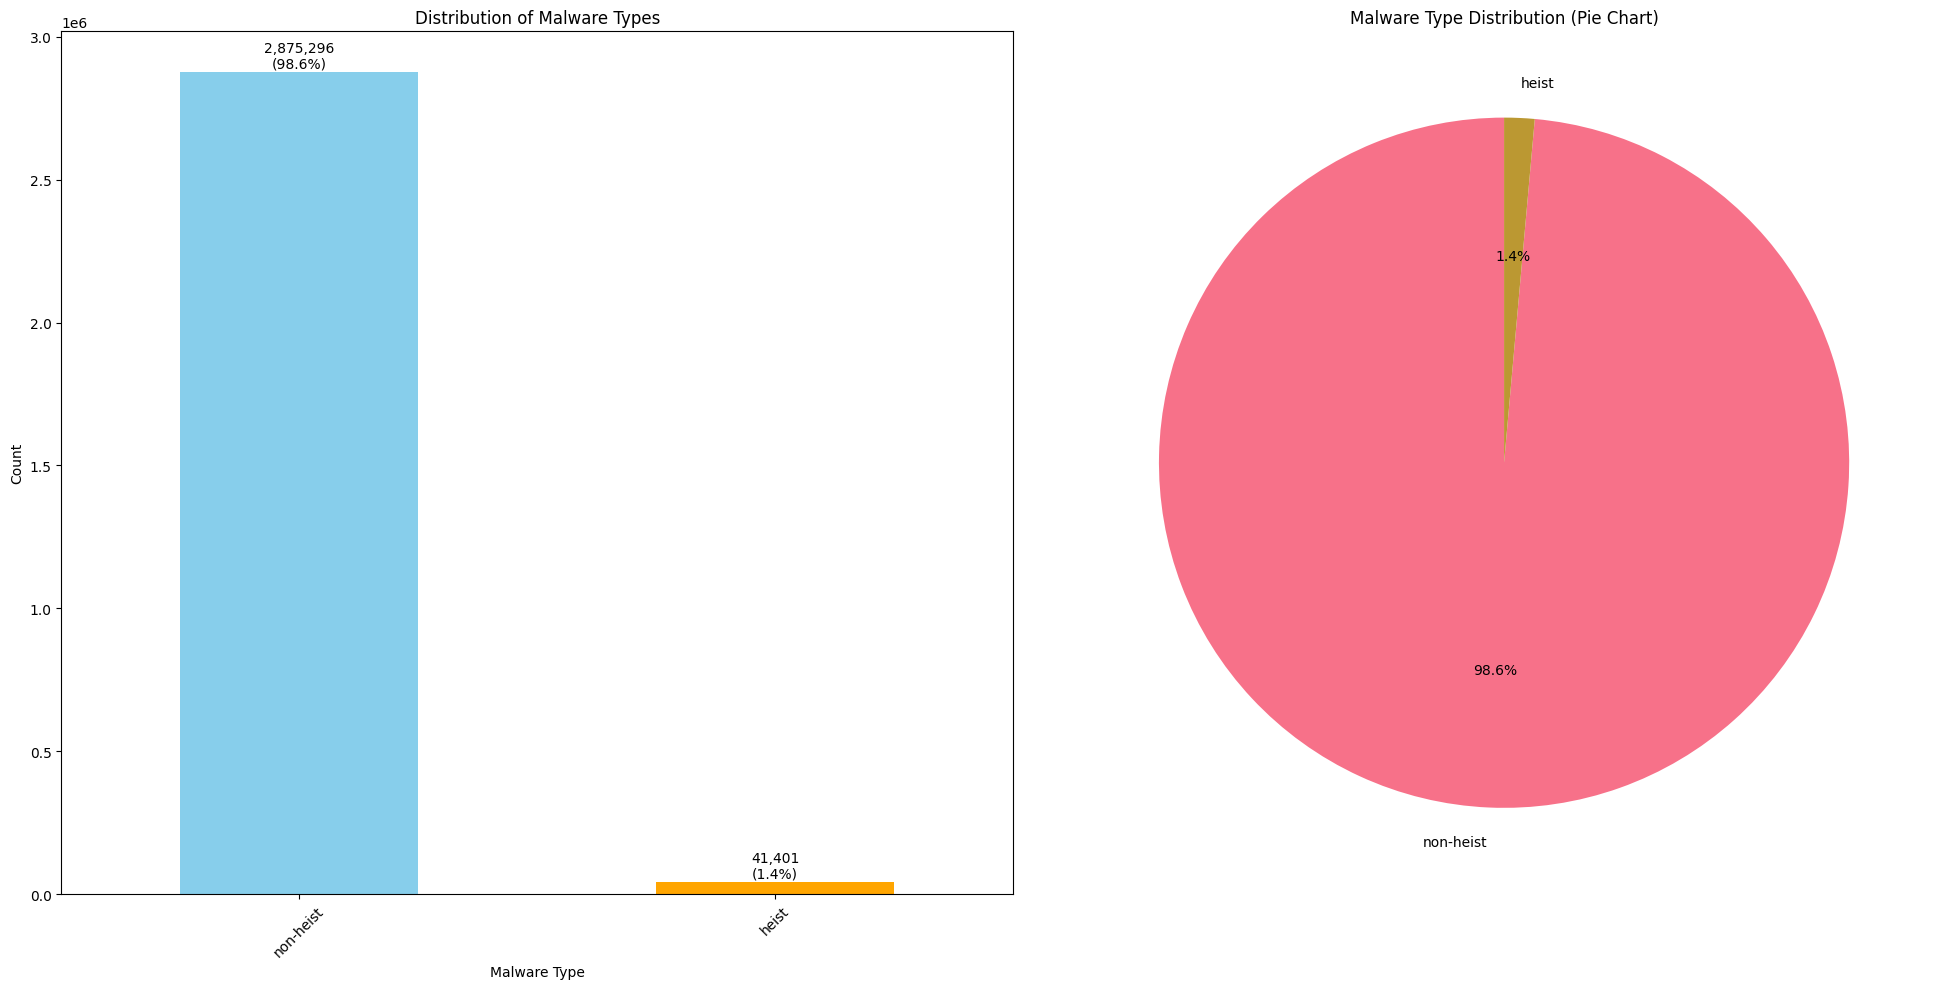

In [ ]:
# Distribution of Malware Types
plt.figure(figsize=(20, 10))

# Malware type counts
malware_counts = df['malware_type'].value_counts().compute() # Convert Dask Series to Pandas Series

# Subplot 1: Bar plot
plt.subplot(1, 2, 1)
malware_counts.plot(kind='bar', color=['skyblue', 'orange'])
plt.title('Distribution of Malware Types')
plt.xlabel('Malware Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Add percentage labels to the bar plot
total = len(df)
for i, v in enumerate(malware_counts.values):
    plt.text(i, v + 5000, f'{v:,}\n({v/total*100:.1f}%)', ha='center', va='bottom')

# Subplot 2: Pie chart
plt.subplot(1, 2, 2)
plt.pie(malware_counts.values, labels=malware_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Malware Type Distribution (Pie Chart)')

# Adjust layout
plt.tight_layout()

# Save the plot to a file
plt.savefig('malware_type_distribution.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()

# Close the plot to avoid further issues in an interactive environment
plt.close()

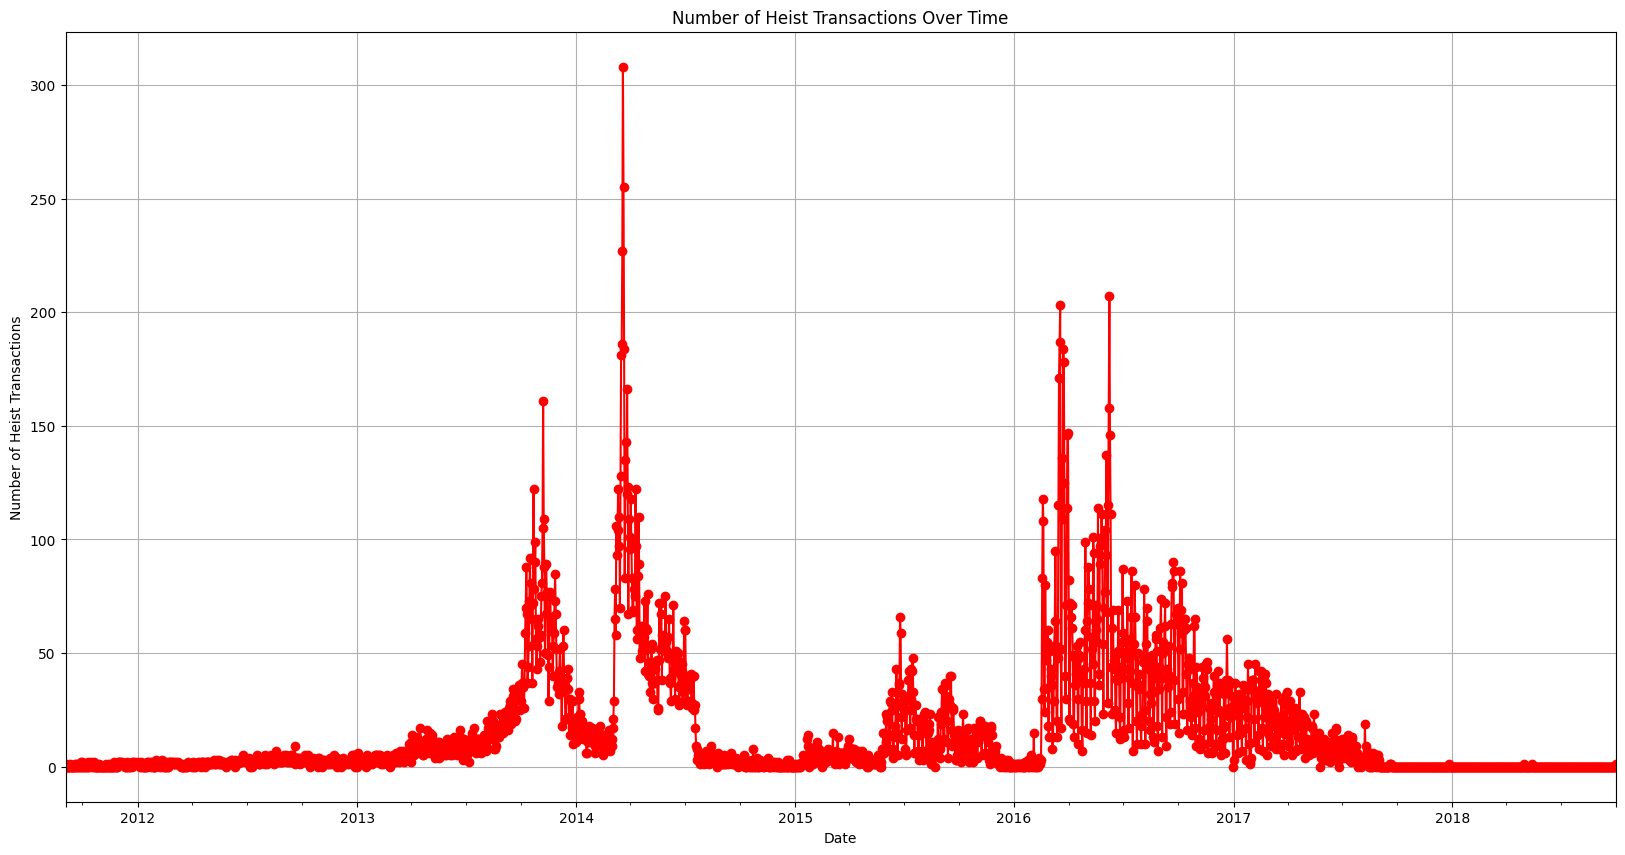

In [ ]:
# Combine 'year' and 'day' to create a 'date' column
df_pandas_date = df[['year', 'day', 'malware_type']].compute()

# Create a datetime string in a format that can be easily parsed
df_pandas_date['date_str'] = df_pandas_date['year'].astype(int).astype(str) + '-' + df_pandas_date['day'].astype(int).astype(str)

# Convert the combined string to datetime objects
df_pandas_date['date'] = pd.to_datetime(df_pandas_date['date_str'], format='%Y-%j', errors='coerce')

# Filter only heist transactions
heist_df_pandas = df_pandas_date[df_pandas_date['malware_type'] == 'heist'].copy()

# Set the date as the index for time series analysis
heist_df_pandas = heist_df_pandas.set_index('date')

# Group by time (daily in this case) and count transactions
heist_counts = heist_df_pandas.resample('D').size()

# Plot Line Chart
plt.figure(figsize=(20, 10))
heist_counts.plot(kind='line', marker='o', color='red')
plt.title('Number of Heist Transactions Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Heist Transactions')
plt.grid(True)

# Save and Show
plt.savefig('heist_transactions_line.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()


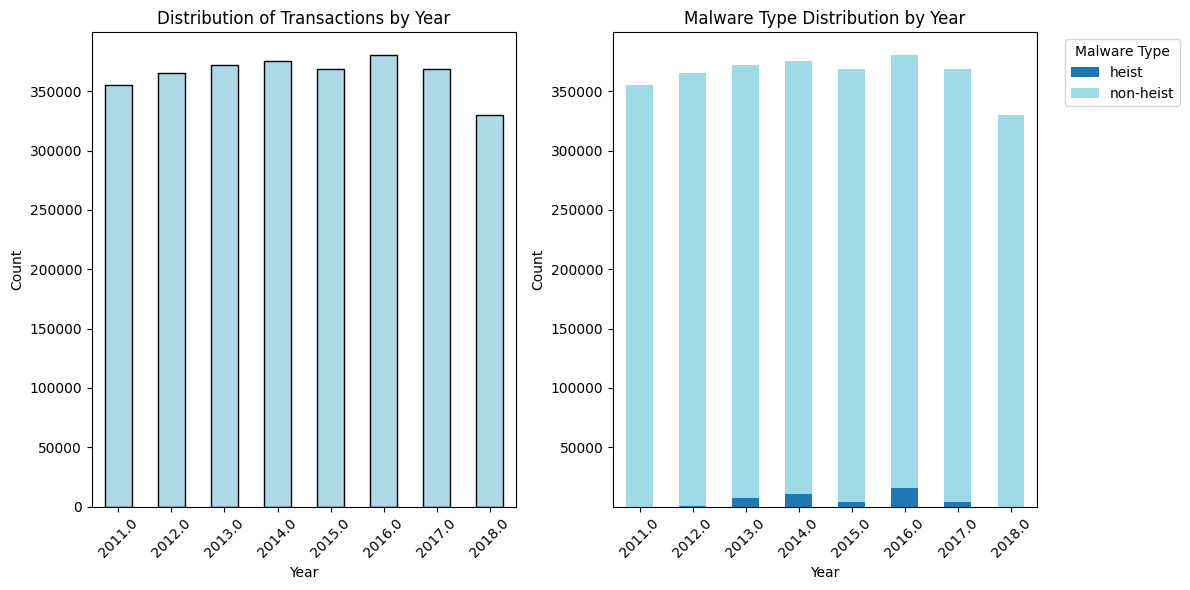

In [ ]:
import matplotlib.pyplot as plt

# Set up the plot with two subplots side-by-side
plt.figure(figsize=(12, 6))

# First subplot: Distribution of Transactions by Year
year_counts = df['year'].value_counts().compute().sort_index()  # Count the number of transactions per year and compute to pandas Series
plt.subplot(1, 2, 1)
year_counts.plot(kind='bar', color='lightblue', edgecolor='black')  # Plot the pandas Series
plt.title('Distribution of Transactions by Year')  # Title of the plot
plt.xlabel('Year')  # X-axis label
plt.ylabel('Count')  # Y-axis label
plt.xticks(rotation=45)  # Rotate X-axis labels for better readability

# Second subplot: Malware Type Distribution by Year
plt.subplot(1, 2, 2)

# Group by year and malware type, compute to pandas DataFrame, and ensure missing values are filled with 0
year_malware = df.groupby(['year', 'malware_type']).size().compute().unstack(fill_value=0)  # Compute to pandas DataFrame

# Ensure years are sorted for the x-axis
year_malware = year_malware.sort_index(axis=0)

# Plot stacked bar chart
year_malware.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='tab20')  # Use tab20 colormap for clarity
plt.title('Malware Type Distribution by Year')  # Title of the plot
plt.xlabel('Year')  # X-axis label
plt.ylabel('Count')  # Y-axis label
plt.xticks(rotation=45)  # Rotate X-axis labels for better readability

# Add legend to distinguish malware types
plt.legend(title='Malware Type', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout for better spacing between subplots
plt.tight_layout()

# Display the plot (ensure both subplots show)
plt.show()



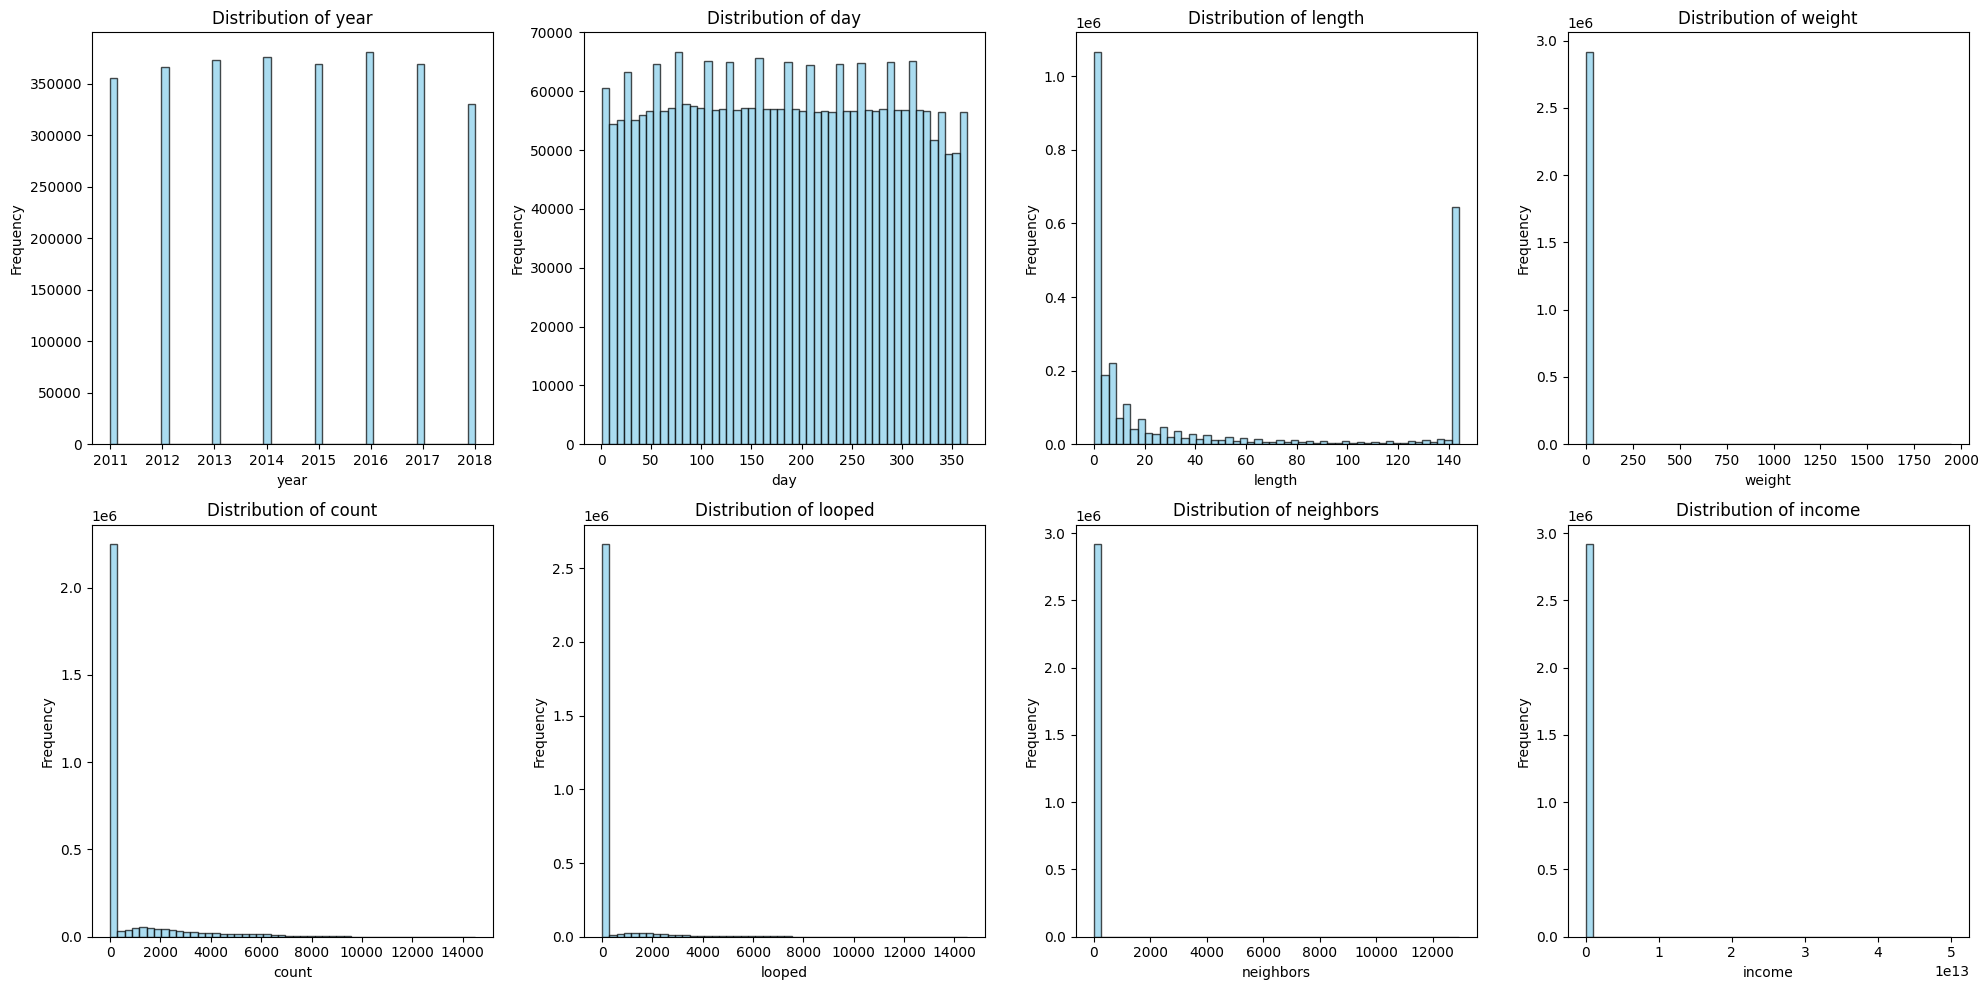

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame and contains the required columns
numerical_features = ['year', 'day', 'length', 'weight', 'count', 'looped', 'neighbors', 'income']

# Create subplots for each feature's distribution
fig, axes = plt.subplots(2, 4, figsize=(20, 10))  # Creating a 2x4 grid of subplots
axes = axes.ravel()  # Flatten the 2D array of axes into 1D

for i, feature in enumerate(numerical_features):
    axes[i].hist(df[feature], bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()  # Display the plot

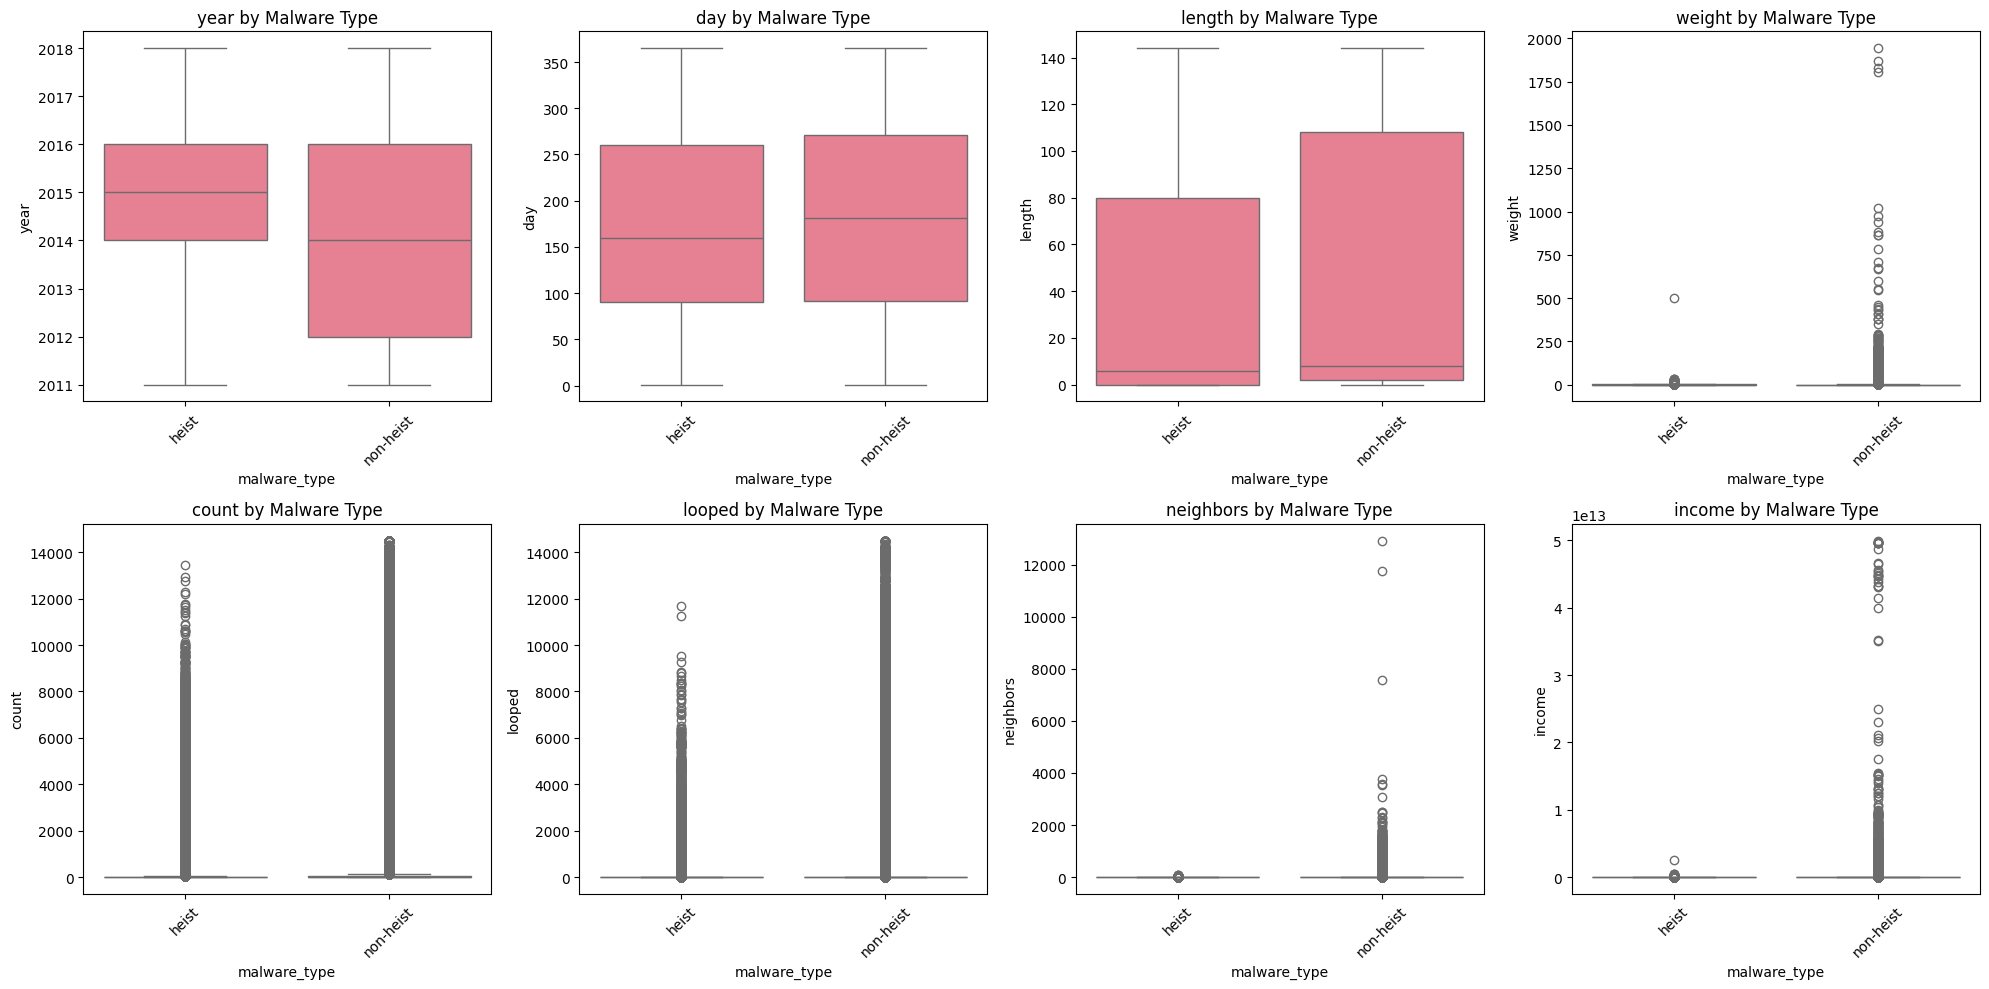

In [ ]:
# 3. Box plots for numerical features by malware type
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, feature in enumerate(numerical_features):
    # Compute the relevant columns to a pandas DataFrame for seaborn
    plot_data = df[['malware_type', feature]].compute()
    sns.boxplot(x='malware_type', y=feature, data=plot_data, ax=axes[i])
    axes[i].set_title(f'{feature} by Malware Type')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()  # This will display the plots in your notebook or Python environment

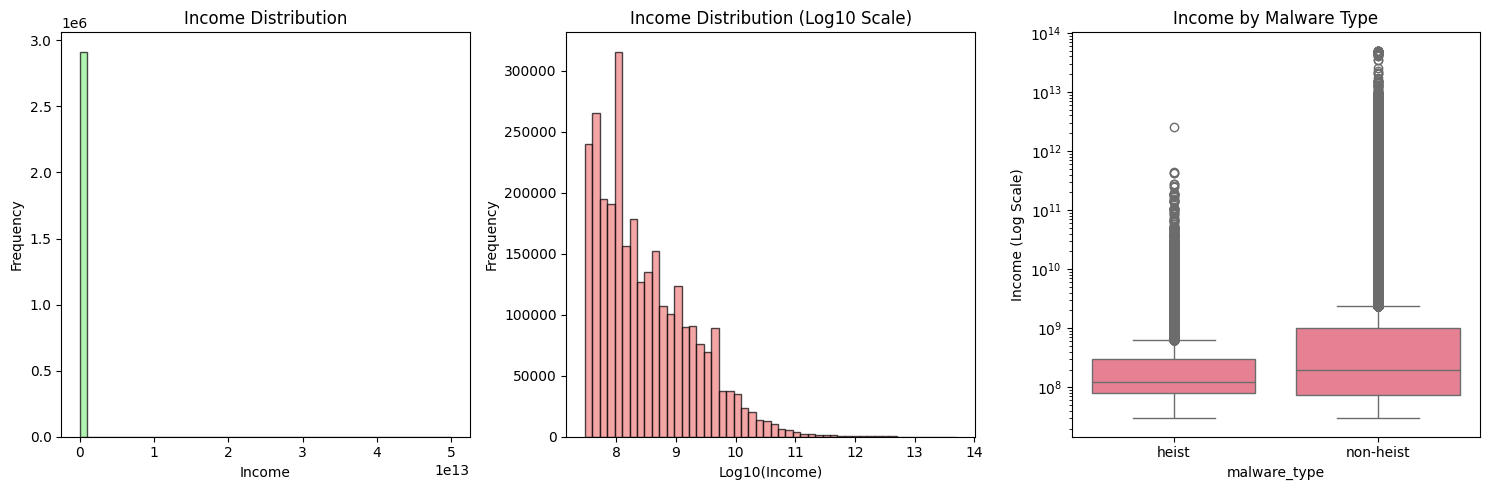

In [ ]:
# Income distribution (log scale due to wide range)
plt.figure(figsize=(15, 5))

# Compute the income data to a pandas Series for plotting
income_data = df['income'].compute()

# Income Distribution (Histogram)
plt.subplot(1, 3, 1)
plt.hist(income_data, bins=50, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Frequency')

# Log10 of Income Distribution (Histogram)
plt.subplot(1, 3, 2)
# Handle potential zero or negative income values before taking the log
plt.hist(np.log10(income_data[income_data > 0]), bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
plt.title('Income Distribution (Log10 Scale)')
plt.xlabel('Log10(Income)')
plt.ylabel('Frequency')

# Income by Malware Type (Boxplot with log scale)
plt.subplot(1, 3, 3)
# Compute the relevant columns to a pandas DataFrame for seaborn
plot_data = df[['malware_type', 'income']].compute()
sns.boxplot(x='malware_type', y='income', data=plot_data)
plt.title('Income by Malware Type')
plt.yscale('log')
plt.ylabel('Income (Log Scale)')

# Adjust layout for better spacing
plt.tight_layout()

# Save the figure as a high-quality PNG file with high resolution
plt.savefig('income_analysis.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()

# Close the plot to free up memory after saving
plt.close()

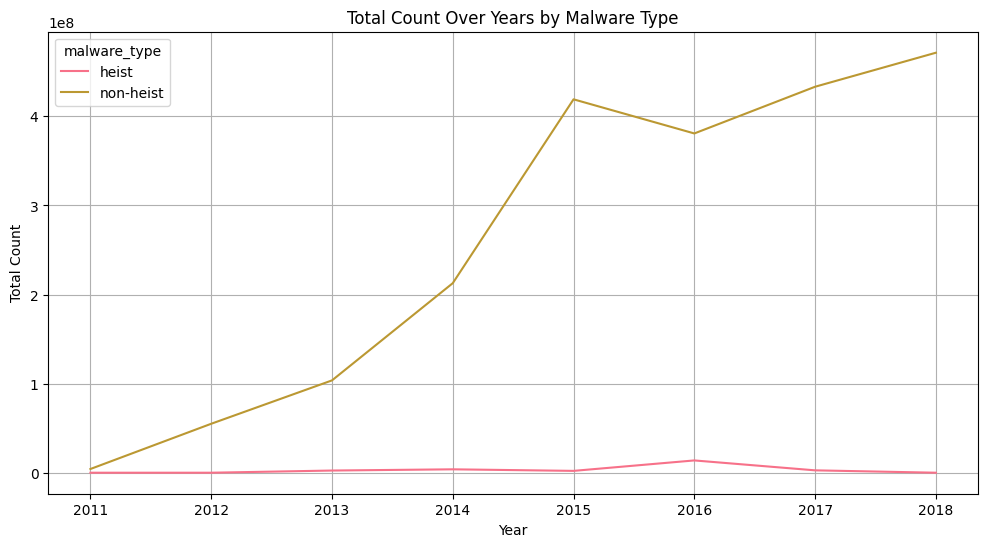

In [ ]:
#Time series plot for total count over years by malware type
count_by_year_malware = df.groupby(["year", "malware_type"])["count"].sum().compute().unstack()
count_by_year_malware.plot(kind="line", figsize=(12, 6))
plt.title("Total Count Over Years by Malware Type")
plt.xlabel("Year")
plt.ylabel("Total Count")
plt.grid(True)
plt.savefig("total_count_time_series.png", dpi=300, bbox_inches="tight")


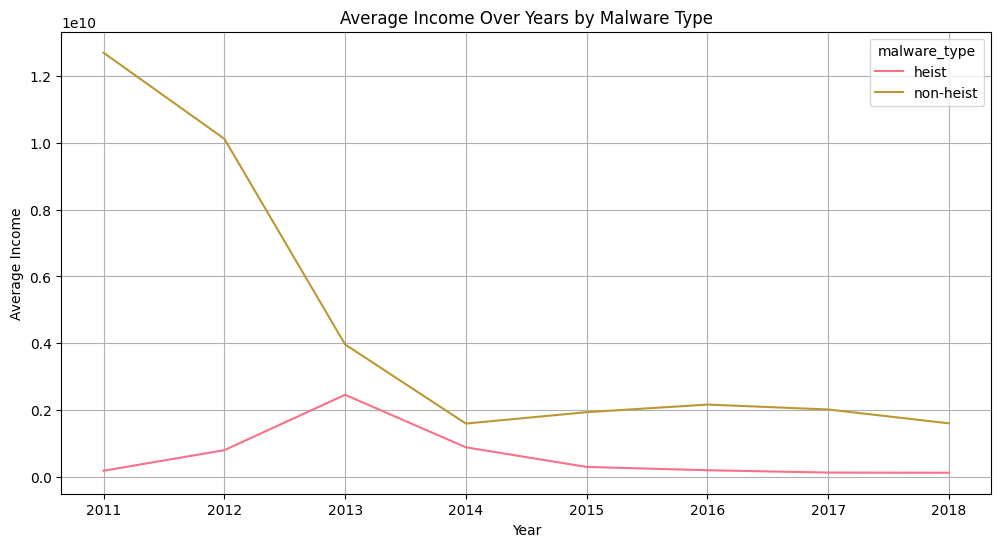

In [ ]:
#Time series plot for average income over years by malware type
income_by_year_malware = df.groupby(["year", "malware_type"])["income"].mean().compute().unstack()
income_by_year_malware.plot(kind="line", figsize=(12, 6))
plt.title("Average Income Over Years by Malware Type")
plt.xlabel("Year")
plt.ylabel("Average Income")
plt.grid(True)
plt.savefig("avg_income_time_series.png", dpi=300, bbox_inches="tight")


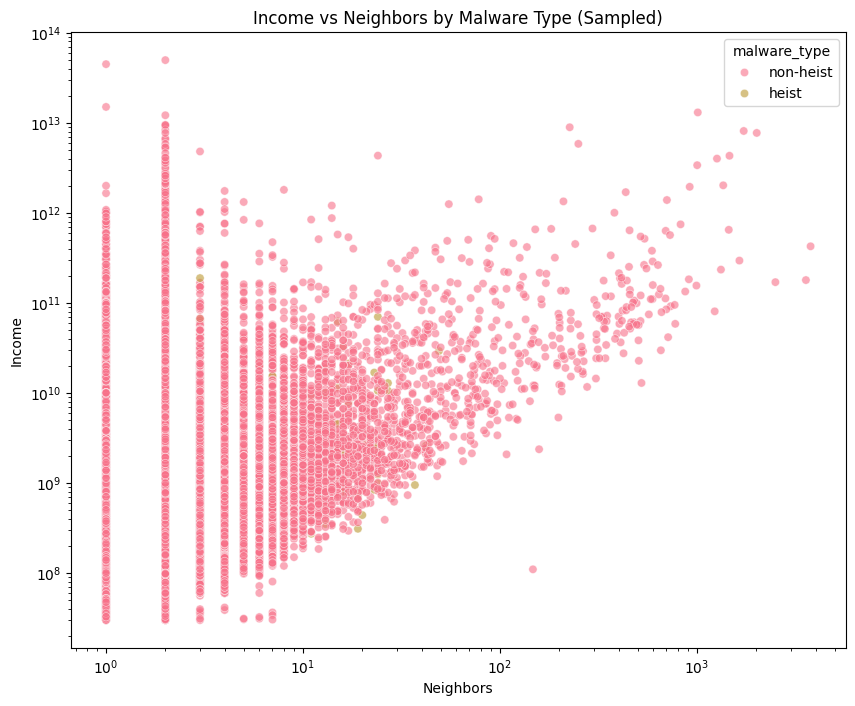

In [ ]:
# Scatter plot for income vs neighbors
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df.sample(frac=0.1, random_state=42).compute()
, x="neighbors", y="income", hue="malware_type", alpha=0.6)
plt.title("Income vs Neighbors by Malware Type (Sampled)")
plt.xlabel("Neighbors")
plt.ylabel("Income")
plt.xscale("log")
plt.yscale("log")
plt.savefig("income_neighbors_scatter.png", dpi=300, bbox_inches="tight")
plt.show()



Unique addresses: 2631095


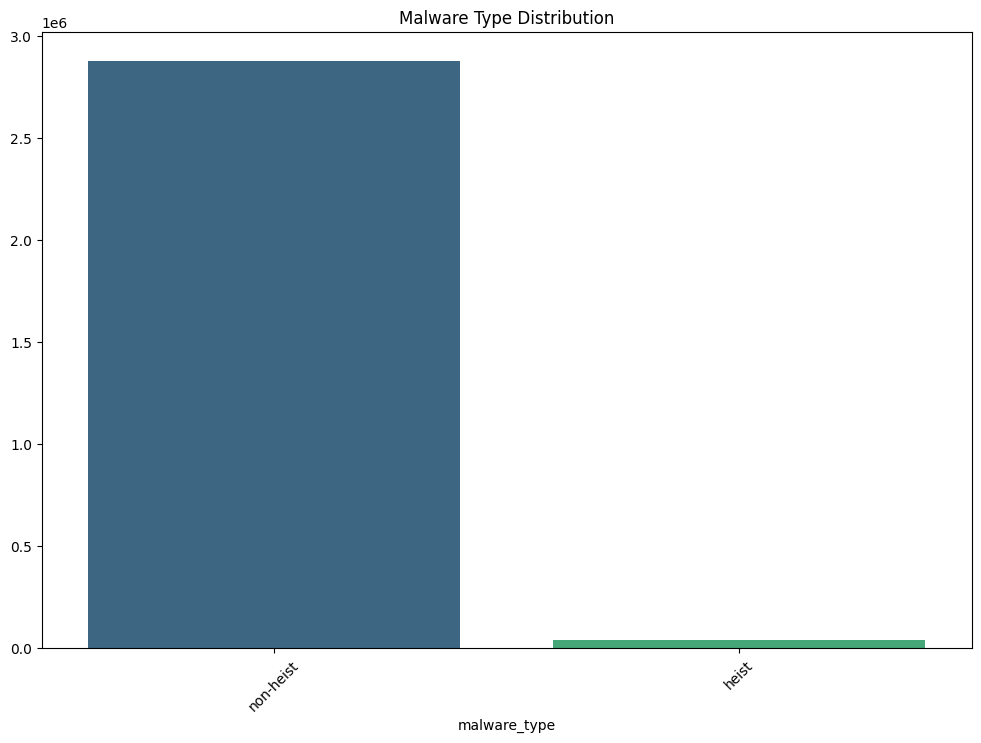

In [ ]:
# Address → too unique for frequency plot (can drop later for ML)
print("Unique addresses:", df['address'].nunique().compute())

# Malware type → frequency
malware_counts = df['malware_type'].value_counts().compute()
sns.barplot(x=malware_counts.index, y=malware_counts.values, palette="viridis")
plt.title("Malware Type Distribution")
plt.xticks(rotation=45)
plt.show()

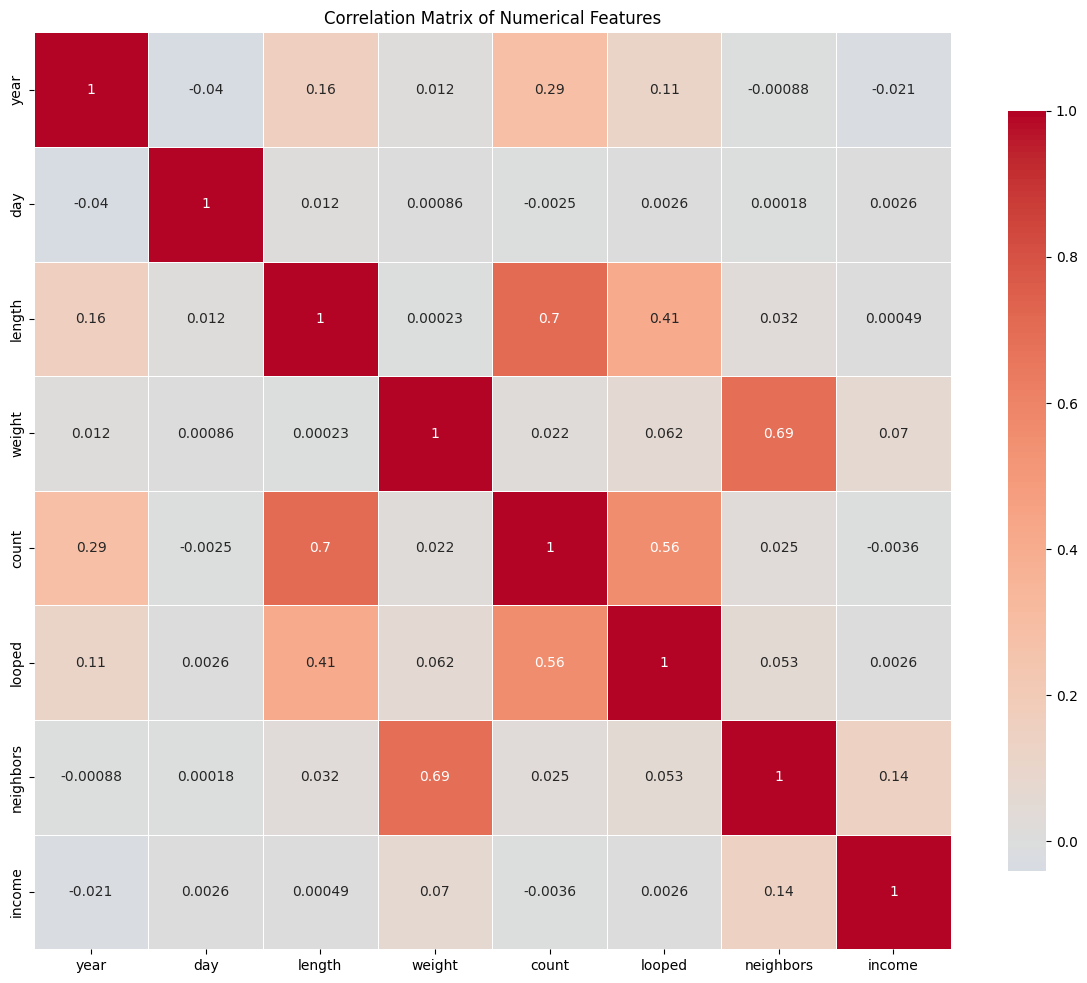

<Figure size 1200x800 with 0 Axes>

In [ ]:
# List of numerical features you want to consider
numerical_features = ['year', 'day', 'length', 'weight', 'count', 'looped', 'neighbors', 'income']

# Compute the correlation matrix (Dask's `.corr()` will work similarly to pandas but on Dask dataframe)
correlation_matrix = df[numerical_features].compute().corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": .8})

# Title and layout adjustments
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()

# Show the plot
plt.show()

# To save it as a high-quality image
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')


In [ ]:
!pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 89.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.9/232.9 kB 15.7 MB/s eta 0:00:00


In [ ]:
import dask.dataframe as dd
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Step 2: Select numerical features for the VIF calculation
numerical_features = ['year', 'day', 'length', 'weight', 'count', 'looped', 'neighbors', 'income']

# Step 3: Subset the dataframe to only include the numerical columns
df_numeric = df[numerical_features]

# Step 4: Compute the Dask DataFrame to convert it into a Pandas DataFrame
df_numeric = df_numeric.compute()

# Step 5: Add a constant column for the intercept in VIF calculation
df_numeric = sm.add_constant(df_numeric)

# Step 6: Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["features"] = df_numeric.columns
vif_data["VIF"] = [variance_inflation_factor(df_numeric.values, i) for i in range(df_numeric.shape[1])]

# Step 7: Display the VIF values
print(vif_data)

    features       VIF
0      const  0.000000
1       year  1.098088
2        day  1.002020
3     length  1.993067
4     weight  1.929302
5      count  2.552936
6     looped  1.469263
7  neighbors  1.954711
8     income  1.021498


General Interpretation of VIF:
VIF > 10: Indicates a serious multicollinearity issue, and you should consider removing or combining features.

VIF between 5 and 10: Suggests moderate multicollinearity, which may require attention but isn’t necessarily a deal-breaker.

VIF < 5: Indicates no significant multicollinearity.

Conclusion:
The features in your dataset do not show any major issues with multicollinearity, as all VIF values are below 5.0. Therefore, these features should be safe to include in your model without requiring significant adjustments or removals based on multicollinearity concerns.

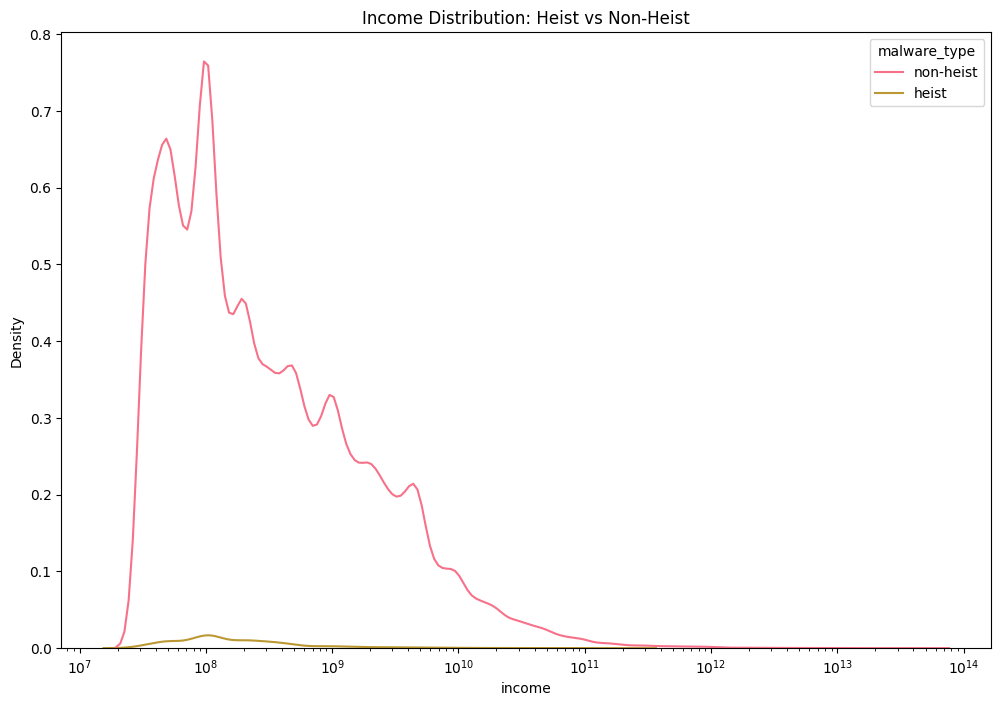

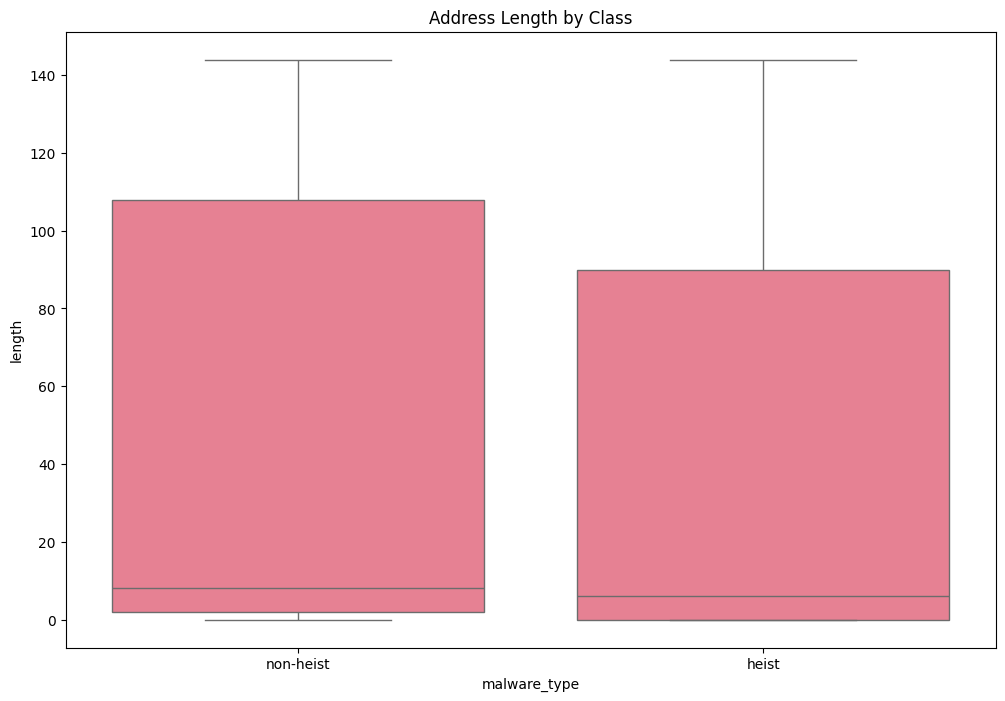

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Create a sampled Pandas DataFrame for plotting
# Sample 10% of the data for plotting to keep it manageable
pdf_sample = df.sample(frac=0.1, random_state=42).compute()

# Example: income distribution
sns.kdeplot(data=pdf_sample, x="income", hue="malware_type", log_scale=True)
plt.title("Income Distribution: Heist vs Non-Heist")
plt.show()

# Example: length vs class
sns.boxplot(data=pdf_sample, x="malware_type", y="length")
plt.title("Address Length by Class")
plt.show()

In [ ]:
Q1 = pdf_sample['income'].quantile(0.25)
Q3 = pdf_sample['income'].quantile(0.75)
IQR = Q3 - Q1
outliers = pdf_sample[(pdf_sample['income'] < Q1 - 1.5*IQR) | (pdf_sample['income'] > Q3 + 1.5*IQR)]
print("Outliers in income:", len(outliers))


Outliers in income: 43046


In [ ]:
import dask.dataframe as dd

def cap_outliers(df, column):
    """
    Caps outliers in a given numerical column using the IQR method.
    Works with Dask DataFrames by computing necessary quantiles.
    """
    Q1 = df[column].quantile(0.25).compute()
    Q3 = df[column].quantile(0.75).compute()
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Apply capping
    df[column] = df[column].map_partitions(
        lambda s: s.clip(lower=lower_bound, upper=upper_bound)
    )
    return df

# Apply to selected numerical columns
num_cols = ["length", "weight", "count", "income", "neighbors"]

for col in num_cols:
    df = cap_outliers(df, col)


In [ ]:
# Convert a sample to pandas for inspection
pdf_sample = df[num_cols].sample(frac=0.001).compute()

print("Summary statistics after capping:")
print(pdf_sample.describe())


Summary statistics after capping:
            length        weight        count        income  neighbors
count  2917.000000  2.917000e+03  2917.000000  2.917000e+03     2917.0
mean     44.137127  4.416573e-01   527.274769  1.043931e+09        2.0
std      58.653013  4.939536e-01  1081.634484  1.792861e+09        0.0
min       0.000000  1.802259e-72     1.000000  3.000000e+07        2.0
25%       2.000000  2.343750e-02     1.000000  7.500000e+07        2.0
50%       8.000000  2.500000e-01     1.000000  1.998619e+08        2.0
75%     100.000000  1.000000e+00    53.000000  9.525064e+08        2.0
max     144.000000  2.406250e+00  3388.500000  6.491408e+09        2.0


In [ ]:

print("EDA visualizations completed and saved!")
print(f"Dataset shape: {df.shape[0].compute(), df.shape[1]}")
print(f"Missing values: {df.isnull().sum().sum().compute()}")
print(f"Malware type distribution:")
print(df['malware_type'].value_counts().compute())
print(f"Percentage of Heist transactions: {(df['malware_type'] == 'heist').mean().compute() * 100:.2f}%")
print(f"Percentage of Non-Heist transactions: {(df['malware_type'] == 'non-heist').mean().compute() * 100:.2f}%")

EDA visualizations completed and saved!
Dataset shape: (2916697, 10)
Missing values: 0
Malware type distribution:
malware_type
non-heist    2875296
heist          41401
Name: count, dtype: int64
Percentage of Heist transactions: 1.42%
Percentage of Non-Heist transactions: 98.58%


In [ ]:
# Drop the 'address' column as it's an identifier and not a feature for modeling-too many unique values, not useful for feature importance
df = df.drop("address", axis=1)

In [ ]:
# ------------------------
# 2. LOAD DATA (Dask)
# ------------------------

X = df.drop("malware_type", axis=1)
y = df["malware_type"]

# Convert Dask → Pandas
X_pd = X.compute()
y_pd = y.compute()


In [ ]:
# ------------------------
# 3. TRAIN/TEST SPLIT
# ------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_pd, y_pd, test_size=0.2, stratify=y_pd, random_state=42
)

In [ ]:
# ------------------------
# 3. MAP TARGET TO {non-heist:0, heist:1}
# ------------------------
mapping = {'non-heist': 0, 'heist': 1}
y_train_encoded = y_train.map(mapping).astype(int)
y_test_encoded  = y_test.map(mapping).astype(int)

# Sanity check: no NaNs after mapping
if y_train_encoded.isna().any() or y_test_encoded.isna().any():
    raise ValueError("Unexpected labels found in target. Ensure only 'heist'/'non-heist' are present.")

# Imbalance ratio for XGBoost (neg/pos)
n_neg = (y_train_encoded == 0).sum()
n_pos = (y_train_encoded == 1).sum()
imbalance_ratio = float(n_neg) / float(n_pos) if n_pos > 0 else 1.0
print(f"Class counts (train): non-heist={n_neg}, heist={n_pos} (ratio={imbalance_ratio:.2f})")

Class counts (train): non-heist=2300236, heist=33121 (ratio=69.45)


In [ ]:
!pip install imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.0/240.0 kB 4.2 MB/s eta 0:00:00


In [ ]:
# Core ML
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Imbalance utils
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
# Optional: XGBoost (guarded import)
xgb_available = True
try:
    from xgboost import XGBClassifier
except Exception:
    xgb_available = False

In [ ]:
# ------------------------
# 4. BUILD PIPELINES (no leakage)
# ------------------------
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# A) Logistic Regression with class_weight (needs scaling)
pipe_lr_weighted = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42, n_jobs=-1))
])

# B) Logistic Regression with SMOTE (SMOTE is applied per fold, safely)
pipe_lr_smote = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1))
])

# C) Random Forest with class_weight
pipe_rf_weighted = Pipeline([
    ("clf", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# D) XGBoost with scale_pos_weight (if available)
pipelines = {
    "LR + class_weight": pipe_lr_weighted,
    "LR + SMOTE": pipe_lr_smote,
    "RF + class_weight": pipe_rf_weighted
}

if xgb_available:
    pipe_xgb = Pipeline([
        ("clf", XGBClassifier(
            eval_metric="logloss",
            scale_pos_weight=imbalance_ratio,
            n_estimators=300,
            max_depth=6,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=42,
            n_jobs=-1
        ))
    ])
    pipelines["XGB + spw"] = pipe_xgb
else:
    print("xgboost not available; skipping XGB model.")


In [ ]:
# ------------------------
# 5. FAIR COMPARISON VIA CV (F1)
# ------------------------
cv_results = {}
for name, mdl in pipelines.items():
    scores = cross_val_score(mdl, X_train, y_train_encoded, cv=cv, scoring="f1", n_jobs=-1)
    cv_results[name] = (scores.mean(), scores.std())
    print(f"{name}: F1={scores.mean():.4f} ± {scores.std():.4f}")

best_name = max(cv_results, key=lambda k: cv_results[k][0])
best_pipe = pipelines[best_name]
print(f"\n Best approach by CV: {best_name} (F1={cv_results[best_name][0]:.4f})")


LR + class_weight: F1=0.0412 ± 0.0005
LR + SMOTE: F1=0.0418 ± 0.0003
RF + class_weight: F1=0.3824 ± 0.0045
XGB + spw: F1=0.2077 ± 0.0009

 Best approach by CV: RF + class_weight (F1=0.3824)


In [ ]:
#get best model
best_model = best_pipe.fit(X_train, y_train_encoded)

In [ ]:
# ------------------------
# 7. FINAL EVALUATION ON TEST SET
# ------------------------
y_pred = best_model.predict(X_test)

# Predict proba if available (some classifiers, e.g., RF/XGB/LR have it)
y_proba = None
try:
    y_proba = best_model.predict_proba(X_test)[:, 1]
except Exception:
    # Some models may only have decision_function; optional:
    try:
        from sklearn.metrics import roc_auc_score
        y_scores = best_model.decision_function(X_test)
        # Scale to [0,1] not needed for ROC-AUC, so we can pass raw scores
        y_proba = y_scores
    except Exception:
        pass

print("\n========== FINAL TEST RESULTS ==========")
print("Confusion Matrix:\n", confusion_matrix(y_test_encoded, y_pred))
print("\nClassification Report:\n", classification_report(
    y_test_encoded, y_pred, target_names=["non-heist", "heist"]
))

if y_proba is not None:
    try:
        print("ROC-AUC:", roc_auc_score(y_test_encoded, y_proba))
    except Exception:
        pass


========== FINAL TEST RESULTS ==========
Confusion Matrix:
 [[574008   1052]
 [  5832   2448]]

Classification Report:
               precision    recall  f1-score   support

   non-heist       0.99      1.00      0.99    575060
       heist       0.70      0.30      0.42      8280

    accuracy                           0.99    583340
   macro avg       0.84      0.65      0.70    583340
weighted avg       0.99      0.99      0.99    583340

ROC-AUC: 0.9273845907026548


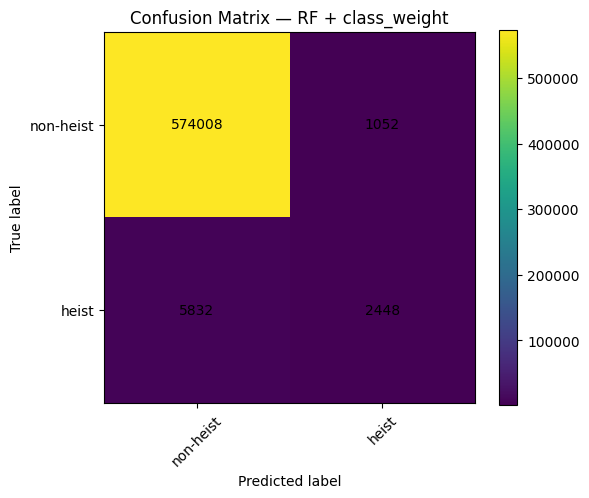

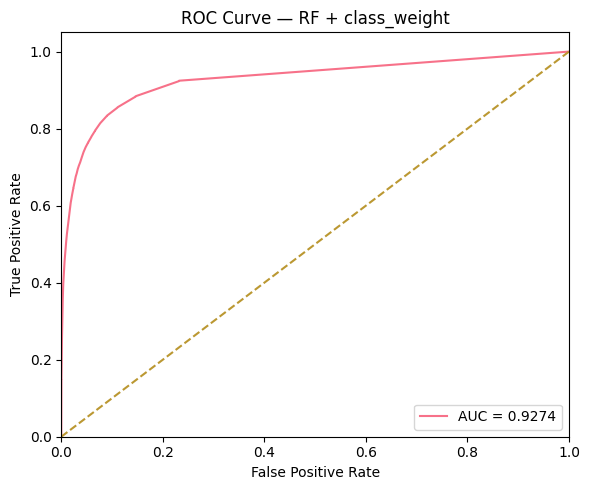

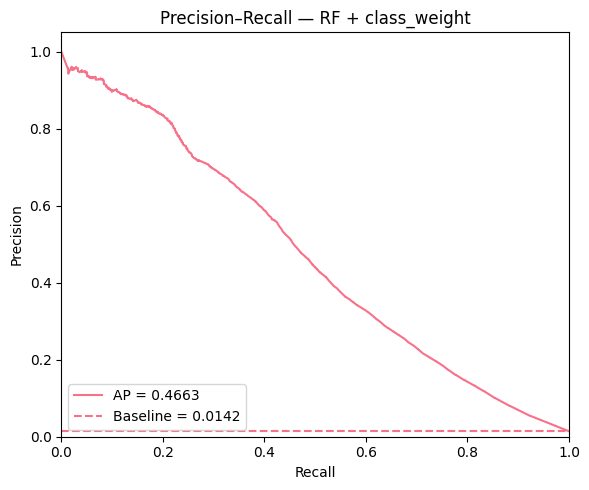

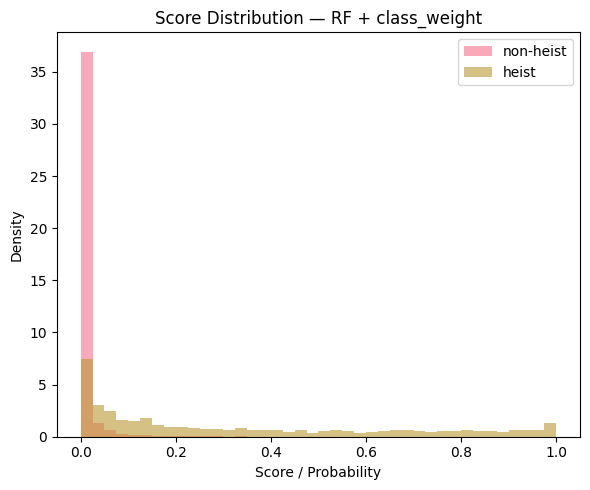

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)

# ---- Confusion Matrix (counts) ----
cm = confusion_matrix(y_test_encoded, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title(f"Confusion Matrix — {best_name}")
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ["non-heist", "heist"], rotation=45)
plt.yticks(tick_marks, ["non-heist", "heist"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], "d"),
                 ha="center", va="center")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

# ---- ROC Curve ----
if y_proba is not None:
    fpr, tpr, _ = roc_curve(y_test_encoded, y_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {best_name}")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    # ---- Precision–Recall Curve ----
    precision, recall, _ = precision_recall_curve(y_test_encoded, y_proba)
    ap = average_precision_score(y_test_encoded, y_proba)
    baseline = float(np.mean(y_test_encoded))  # positive rate

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP = {ap:.4f}")
    plt.hlines(baseline, 0, 1, linestyles="--", label=f"Baseline = {baseline:.4f}")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision–Recall — {best_name}")
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.show()

    # ---- Score / Probability Distribution ----
    plt.figure(figsize=(6, 5))
    plt.hist(y_proba[y_test_encoded == 0], bins=40, alpha=0.6, density=True, label="non-heist")
    plt.hist(y_proba[y_test_encoded == 1], bins=40, alpha=0.6, density=True, label="heist")
    plt.xlabel("Score / Probability")
    plt.ylabel("Density")
    plt.title(f"Score Distribution — {best_name}")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No score/proba available; skipping ROC/PR/score plots.")


In [ ]:
# (Optional) If you want to inspect feature importances for RF/XGB:
if best_name.startswith("RF") or best_name.startswith("XGB"):
    clf = best_model.named_steps["clf"]
    if hasattr(clf, "feature_importances_"):
        import pandas as pd
        fi = pd.Series(clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
        print("\nTop 10 feature importances:")
        print(fi.head(10))


Top 10 feature importances:
year         0.308413
income       0.243798
day          0.186024
weight       0.088912
count        0.049631
neighbors    0.047558
length       0.047238
looped       0.028425
dtype: float64


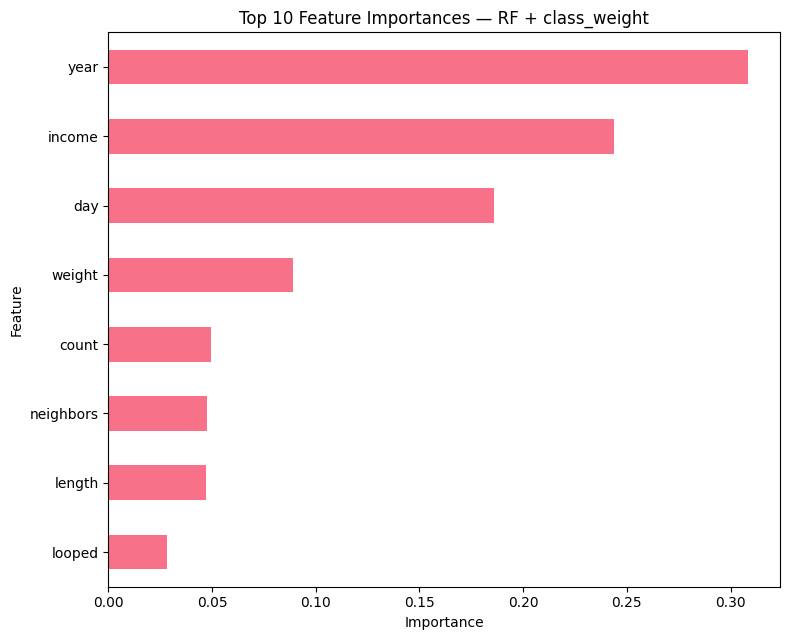

In [ ]:
import matplotlib.pyplot as plt

topk = 10
fi_top = fi.head(topk).sort_values(ascending=True)  # ascending for a clean horizontal barh

plt.figure(figsize=(8, 0.45*topk + 2))
fi_top.plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top {topk} Feature Importances" + (f" — {best_name}" if 'best_name' in globals() else ""))
plt.tight_layout()
plt.show()
